<a href="https://colab.research.google.com/github/sasitha12/CRMCM_CW01_w2052134/blob/main/CRM_CW01_w2052134.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TASK 01**

In [22]:
# Run once. If Colab asks you to restart the runtime after this install, restart it and then Run all again.
%pip install -q yfinance lxml html5lib

In [23]:
# SETUP | Imports, study parameters and switches
import os, io, sys, json, time, glob, shutil, hashlib, subprocess, warnings, datetime as dt
import numpy as np, pandas as pd, requests, yfinance as yf
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Tight layout")

START, END, BENCH = "2021-01-01", "2025-01-01", "^GSPC"    # study period fixed by the brief; END is exclusive in yfinance
USE_GOOGLE_DRIVE = True   # True: keep data/ in your Google Drive so the snapshot survives Colab resets
REPO_URL = "https://github.com/sasitha12/CRMCM_CW01_w2052134.git"
ALLOW_LIVE_DOWNLOAD = False   # setting to False after the first successful run: the notebook can then never download again by accident

DATA_DIR = "data"
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/CWK1_snapshot/data"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, condition, hard=True):
    """Print a validation result. hard=True stops the notebook on failure; hard=False only flags it for review."""
    ok = bool(condition)
    print(("PASSED: " if ok else ("FAILED: " if hard else "REVIEW: ")) + name)
    if hard:
        assert ok, name
    return ok

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150)
    plt.show()

print("python  ", sys.version.split()[0])
for name, mod in [("pandas", pd), ("numpy", np), ("yfinance", yf), ("requests", requests)]:
    print(f"{name:8s}", mod.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
python   3.13.18
pandas   2.2.3
numpy    2.4.6
yfinance 0.2.66
requests 2.32.4


# **Task 1.1**

In [24]:
# TASK 1.1 | Part A: ticker list + daily prices - use the saved snapshot, or download once and save it
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
FIELDS = {"open": "Open", "high": "High", "low": "Low", "close": "Close", "adj_close": "Adj Close",
          "volume": "Volume", "dividends": "Dividends", "splits": "Stock Splits"}
list_path, info_path = f"{DATA_DIR}/sp500_constituents.csv", f"{DATA_DIR}/snapshot_info.json"
raw_paths = {k: f"{DATA_DIR}/raw_{k}.csv" for k in FIELDS}

def md5(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()[:8]

def snapshot_complete():
    return all(os.path.exists(p) for p in [list_path, info_path, *raw_paths.values()])

def fetch_live():
    """Scrape the ticker list with pandas and download prices with yfinance, then save everything as the snapshot."""
    retrieved = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    page = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (university coursework 6BUIS017W)"}, timeout=30)
    page.raise_for_status()
    cons = pd.read_html(io.StringIO(page.text), match="Symbol")[0]
    cons = cons.rename(columns={"Symbol": "wiki_symbol", "Security": "company", "GICS Sector": "sector", "GICS Sub-Industry": "sub_industry"})
    cons["ticker"] = cons["wiki_symbol"].astype(str).str.strip().str.replace(".", "-", regex=False)   # Yahoo style: BRK.B -> BRK-B
    assert cons["ticker"].is_unique, "duplicate tickers in the list"
    cons["retrieved_utc"] = retrieved
    cons.to_csv(list_path, index=False)

    all_tickers = [BENCH] + cons["ticker"].tolist()
    chunks, dup_dates = [], 0
    for i in range(0, len(all_tickers), 50):                                   # smaller batches, no threads, short pause: gentler on Yahoo's rate limits
        batch = all_tickers[i:i + 50]
        print(f"Downloading {i + 1}-{i + len(batch)} of {len(all_tickers)} ...")
        df = None
        for attempt in range(3):
            try:
                df = yf.download(batch, start=START, end=END, auto_adjust=False, actions=True,
                                 group_by="column", progress=False, threads=False)
                if df is not None and not df.empty:
                    break
            except Exception as e:
                print("   retrying after error:", e)
            time.sleep(5 * (attempt + 1))
        if df is None or df.empty:
            print("   this batch failed after retries")
            continue
        if not isinstance(df.columns, pd.MultiIndex):
            df.columns = pd.MultiIndex.from_product([df.columns, [batch[0]]])
        dup_dates += int(df.index.duplicated().sum())
        chunks.append(df[~df.index.duplicated(keep="last")])
        time.sleep(1)
    assert chunks, "No price data could be downloaded and there is no saved snapshot"

    for key, col in FIELDS.items():
        p = pd.concat([c[col] for c in chunks if col in c.columns.get_level_values(0)], axis=1)
        p.index = pd.to_datetime(p.index).tz_localize(None).normalize()
        p.index.name = "Date"
        p = p.loc[:, ~p.columns.duplicated()].reindex(columns=all_tickers)       # tickers that failed stay as all-NaN columns
        p.to_csv(raw_paths[key])
    info = {"retrieved_utc": retrieved, "ticker_source": WIKI_URL,
            "price_source": f"yfinance {yf.__version__} (auto_adjust=False, actions=True, daily)",
            "study_start": START, "study_end_exclusive": END, "benchmark": BENCH, "duplicate_dates_dropped": dup_dates,
            "package_versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "yfinance": yf.__version__},
            "md5": {k: md5(p) for k, p in raw_paths.items()}}
    json.dump(info, open(info_path, "w"), indent=2)

if not snapshot_complete() and REPO_URL:
    try:
        shutil.rmtree("repo_copy", ignore_errors=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "repo_copy"], check=True)
        shutil.copytree("repo_copy/data", DATA_DIR, dirs_exist_ok=True)
        print("Copied the snapshot from the GitHub repository.")
    except Exception as e:
        print("Could not use the repository snapshot:", e)

if snapshot_complete():
    print("Using the saved snapshot in", DATA_DIR)
elif ALLOW_LIVE_DOWNLOAD:
    print("No saved snapshot found - downloading live (first run only, a few minutes)...")
    fetch_live()
else:
    raise RuntimeError("No saved snapshot found and ALLOW_LIVE_DOWNLOAD is False. Restore data/ from Google Drive, the backup zip or GitHub instead of downloading again.")

# From here on the notebook always reads the saved files, so a first run and a later run follow exactly the same path
info = json.load(open(info_path))
for k, p in raw_paths.items():
    check(f"{k} file matches the checksum recorded in the snapshot manifest ({md5(p)})", md5(p) == info["md5"][k])
constituents = pd.read_csv(list_path)
panels = {k: pd.read_csv(p, index_col=0, parse_dates=True) for k, p in raw_paths.items()}
TICKERS = constituents["ticker"].tolist()
ALL = [BENCH] + TICKERS
panels = {k: p.reindex(columns=ALL) for k, p in panels.items()}

Using the saved snapshot in /content/drive/MyDrive/CWK1_snapshot/data
PASSED: open file matches the checksum recorded in the snapshot manifest (c4cea66a)
PASSED: high file matches the checksum recorded in the snapshot manifest (d961d1db)
PASSED: low file matches the checksum recorded in the snapshot manifest (5d6efe75)
PASSED: close file matches the checksum recorded in the snapshot manifest (240665b9)
PASSED: adj_close file matches the checksum recorded in the snapshot manifest (22bea169)
PASSED: volume file matches the checksum recorded in the snapshot manifest (904dc1b9)
PASSED: dividends file matches the checksum recorded in the snapshot manifest (2389b774)
PASSED: splits file matches the checksum recorded in the snapshot manifest (fac6c376)


Snapshot retrieved (UTC): 2026-11-19 10:27 UTC
Price source: yfinance 0.2.66 (auto_adjust=False, actions=True, daily)
Tickers in the Wikipedia list: 503 | price panel (dates x tickers): (1005, 504)
Date range: 2021-01-04 to 2024-12-31
Tickers changed by the dot->hyphen rule: [['BRK.B', 'BRK-B'], ['BF.B', 'BF-B']]
Sector counts: {'Industrials': 83, 'Information Technology': 76, 'Financials': 76, 'Health Care': 60, 'Consumer Discretionary': 47, 'Consumer Staples': 33, 'Utilities': 31, 'Real Estate': 30, 'Materials': 24, 'Communication Services': 22, 'Energy': 21}
Tickers with no price data at all in the study period: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Raw file checksums: {'open': 'c4cea66a', 'high': 'd961d1db', 'low': '5d6efe75', 'close': '240665b9', 'adj_close': '22bea169', 'volume': '904dc1b9', 'dividends': '2389b774', 'splits': 'fac6c376'}


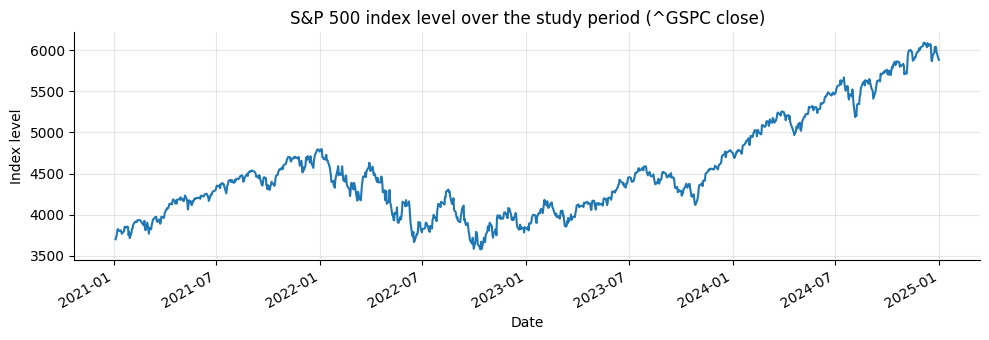

In [25]:
# TASK 1.1 | Part B: snapshot summary and benchmark context
print("Snapshot retrieved (UTC):", info["retrieved_utc"])
print("Price source:", info["price_source"])
print("Tickers in the Wikipedia list:", len(TICKERS), "| price panel (dates x tickers):", panels["close"].shape)
print("Date range:", panels["close"].index.min().date(), "to", panels["close"].index.max().date())
print("Tickers changed by the dot->hyphen rule:", constituents.loc[constituents["wiki_symbol"] != constituents["ticker"], ["wiki_symbol", "ticker"]].values.tolist())
print("Sector counts:", constituents["sector"].value_counts().to_dict())
print("Tickers with no price data at all in the study period:", [t for t in ALL if panels["close"][t].notna().sum() == 0])
print("Raw file checksums:", info["md5"])

panels["close"][BENCH].dropna().plot(figsize=(10, 3.5), title="S&P 500 index level over the study period (^GSPC close)")
plt.ylabel("Index level")
save_fig("fig01_benchmark_level")

## Task 1.2

In [26]:
# TASK 1.2 | Part A: benchmark calendar, per-share quality checks, exclusion rules and the inclusion/exclusion log
trading_days = panels["close"][BENCH].dropna().index          # the benchmark's own dates are the reference trading calendar
n_days = len(trading_days)
check("benchmark calendar has no duplicate dates and is sorted", trading_days.is_unique and trading_days.is_monotonic_increasing)
check("benchmark prices are positive", (panels["close"][BENCH].dropna() > 0).all() and (panels["adj_close"][BENCH].dropna() > 0).all())
check("benchmark dates lie inside the study period", trading_days.min() >= pd.Timestamp(START) and trading_days.max() < pd.Timestamp(END))
check("no duplicate dates in the saved price data", panels["close"].index.is_unique)
print(f"Benchmark calendar: {n_days} trading days, {trading_days[0].date()} to {trading_days[-1].date()}")
print("Trading days per year:", trading_days.year.value_counts().sort_index().to_dict())
print("Duplicate dates dropped at download time:", info.get("duplicate_dates_dropped", "n/a"))

# Align every share to the benchmark calendar. Missing values stay missing (nothing is filled).
close = panels["close"].reindex(trading_days)[TICKERS]
adj = panels["adj_close"].reindex(trading_days)[TICKERS]
vol = panels["volume"].reindex(trading_days)[TICKERS]
divs = panels["dividends"].reindex(trading_days)[TICKERS].fillna(0)      # action tables: no event recorded = 0 (not a price fill)
splits = panels["splits"].reindex(trading_days)[TICKERS].fillna(0)
check("every share date is a benchmark trading date",
      len(panels["close"][TICKERS].dropna(how="all").index.difference(trading_days)) == 0, hard=False)

def internal_gaps(df):      # missing values BETWEEN a share's first and last valid date
    return df.apply(lambda s: int(s.loc[s.first_valid_index():s.last_valid_index()].isna().sum()) if s.notna().any() else 0)

chk = pd.DataFrame(index=TICKERS)
chk["first_valid"] = pd.to_datetime(close.apply(lambda s: s.first_valid_index()))
chk["last_valid"] = pd.to_datetime(close.apply(lambda s: s.last_valid_index()))
chk["n_valid"] = close.notna().sum()
chk["gaps"] = internal_gaps(close) + internal_gaps(adj) + internal_gaps(vol)
chk["nonpositive_price_days"] = ((close <= 0) | (adj <= 0)).sum()
chk["negative_volume_days"] = (vol < 0).sum()
chk["zero_volume_days"] = (vol == 0).sum()
check("Close, Adj Close and Volume have the same number of valid values for every share",
      ((close.notna().sum() == adj.notna().sum()) & (close.notna().sum() == vol.notna().sum())).all(), hard=False)

def reasons(r):
    if r["n_valid"] == 0:
        return "No price data in study period"
    out = []
    if r["first_valid"] > trading_days[0] or r["last_valid"] < trading_days[-1]:
        out.append("Incomplete history (does not cover full study period)")
    if r["gaps"] > 0:
        out.append("Missing values inside history")
    if r["nonpositive_price_days"] > 0:
        out.append("Non-positive price")
    if r["negative_volume_days"] > 0 or r["zero_volume_days"] > 0:
        out.append("Volume error (zero or negative volume)")
    return "; ".join(out)

chk["exclusion_reason"] = chk.apply(reasons, axis=1)
chk["included"] = chk["exclusion_reason"].eq("")
inclusion_log = constituents.set_index("ticker")[["company", "sector", "Date added"]].join(chk)
inclusion_log.to_csv(f"{DATA_DIR}/inclusion_exclusion_log.csv")
included = inclusion_log.index[inclusion_log["included"]].tolist()

print(f"\nIncluded: {len(included)}   Excluded: {int((~inclusion_log['included']).sum())}")
print(inclusion_log.loc[~inclusion_log["included"], "exclusion_reason"].value_counts().to_string())
print(inclusion_log.loc[~inclusion_log["included"], ["company", "Date added", "first_valid", "n_valid", "zero_volume_days", "exclusion_reason"]].to_string())

# Retained shares: complete, positive, identical calendar
c_inc, a_inc, v_inc = close[included], adj[included], vol[included]
check("retained shares have complete histories on the benchmark calendar", (c_inc.notna().all() & a_inc.notna().all() & v_inc.notna().all()).all())
check("retained shares have positive prices and volumes", ((c_inc > 0) & (a_inc > 0) & (v_inc > 0)).all().all())

# Observation date for RFM: final trading date on which the benchmark and every retained share have data
OBS_DATE = pd.concat([c_inc, a_inc, v_inc], axis=1).dropna(how="any").index.max()
print("Observation date (final common completed trading date):", OBS_DATE.date())

PASSED: benchmark calendar has no duplicate dates and is sorted
PASSED: benchmark prices are positive
PASSED: benchmark dates lie inside the study period
PASSED: no duplicate dates in the saved price data
Benchmark calendar: 1005 trading days, 2021-01-04 to 2024-12-31
Trading days per year: {2021: 252, 2022: 251, 2023: 250, 2024: 252}
Duplicate dates dropped at download time: 0
PASSED: every share date is a benchmark trading date
PASSED: Close, Adj Close and Volume have the same number of valid values for every share

Included: 486   Excluded: 17
exclusion_reason
Incomplete history (does not cover full study period)    10
No price data in study period                             5
Volume error (zero or negative volume)                    2
                     company  Date added first_valid  n_valid  zero_volume_days                                       exclusion_reason
ticker                                                                                                             

In [27]:
# TASK 1.2 | Part A2: OHLC consistency check on the retained shares (High >= Low; Open and Close inside the day's range)
o_inc = panels["open"].reindex(trading_days)[included]
h_inc = panels["high"].reindex(trading_days)[included]
l_inc = panels["low"].reindex(trading_days)[included]
eps = 1e-6                                              # tolerance for floating-point rounding
bad = ((h_inc < l_inc * (1 - eps)) | (o_inc > h_inc * (1 + eps)) | (o_inc < l_inc * (1 - eps))
       | (c_inc > h_inc * (1 + eps)) | (c_inc < l_inc * (1 - eps)))
rows = [(t, d.date().isoformat(), float(o_inc.at[d, t]), float(h_inc.at[d, t]), float(l_inc.at[d, t]), float(c_inc.at[d, t]),
         bool(o_inc.at[d, t] > h_inc.at[d, t] * (1 + eps) or o_inc.at[d, t] < l_inc.at[d, t] * (1 - eps)),
         bool(c_inc.at[d, t] > h_inc.at[d, t] * (1 + eps) or c_inc.at[d, t] < l_inc.at[d, t] * (1 - eps)))
        for t in bad.columns for d in bad.index[bad[t]]]
ohlc_anomalies = pd.DataFrame(rows, columns=["ticker", "date", "open", "high", "low", "close", "open_outside_range", "close_outside_range"])
ohlc_anomalies.to_csv(f"{DATA_DIR}/ohlc_anomalies.csv", index=False)

print(f"OHLC anomalies among retained shares: {len(ohlc_anomalies)} of {bad.size} share-days ({100 * len(ohlc_anomalies) / bad.size:.5f}%)")
print(ohlc_anomalies.to_string(index=False) if len(ohlc_anomalies) else "none")
check("OHLC anomalies are rare (fewer than 0.01% of share-days)", len(ohlc_anomalies) < 0.0001 * bad.size, hard=False)
print("Close-outside-range anomalies (these would matter, because Close drives returns and Monetary):", int(ohlc_anomalies["close_outside_range"].sum()) if len(ohlc_anomalies) else 0)
print("Open-only anomalies are harmless here: Open is not used in any feature.")

OHLC anomalies among retained shares: 1 of 488430 share-days (0.00020%)
ticker       date       open       high        low      close  open_outside_range  close_outside_range
  HUBB 2021-05-05 195.979996 198.639999 196.210007 198.130005                True                False
PASSED: OHLC anomalies are rare (fewer than 0.01% of share-days)
Close-outside-range anomalies (these would matter, because Close drives returns and Monetary): 0
Open-only anomalies are harmless here: Open is not used in any feature.


FERG: 27 zero-volume days of 1005 | first 2021-01-07, last 2021-03-05 | median volume on other days 803,550 | adjusted price unchanged on 100% of zero-volume days
SW: 424 zero-volume days of 1005 | first 2021-01-05, last 2024-07-05 | median volume on other days 600 | adjusted price unchanged on 99% of zero-volume days


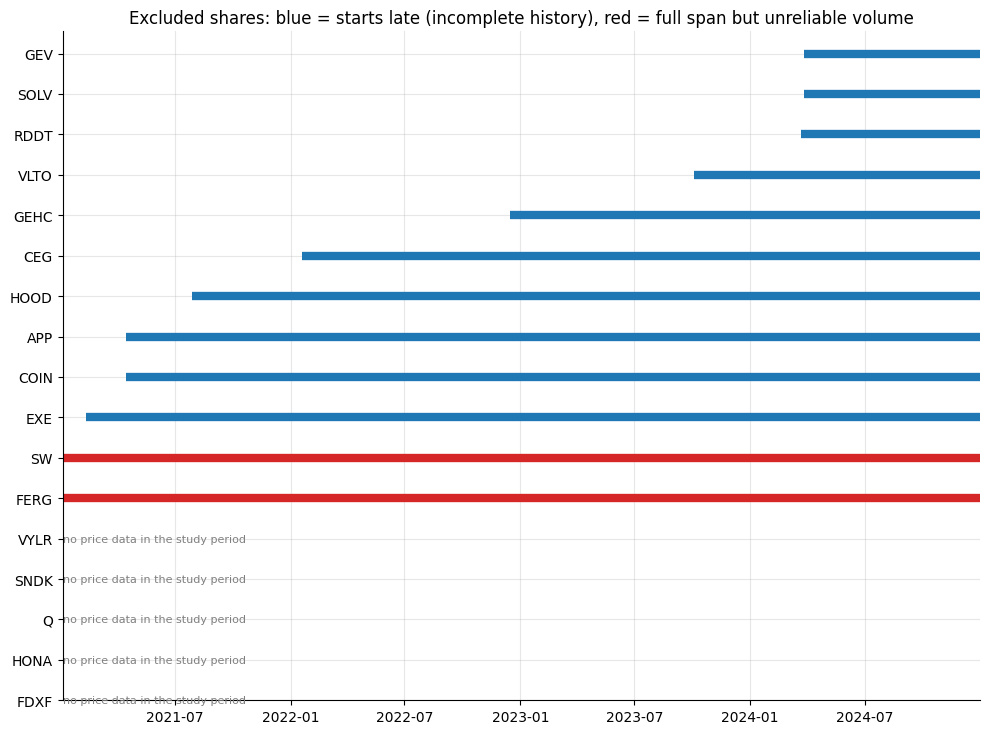

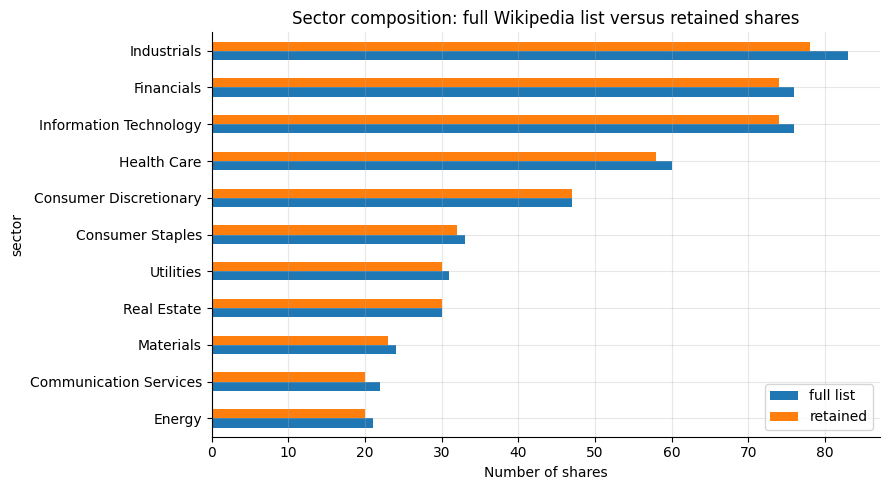

                        full list  retained  pct_excluded
sector                                                   
Industrials                    83        78           6.0
Information Technology         76        74           2.6
Financials                     76        74           2.6
Health Care                    60        58           3.3
Consumer Discretionary         47        47           0.0
Consumer Staples               33        32           3.0
Utilities                      31        30           3.2
Real Estate                    30        30           0.0
Materials                      24        23           4.2
Communication Services         22        20           9.1
Energy                         21        20           4.8


In [28]:
# TASK 1.2 | Part B: evidence behind the exclusions (zero-volume shares) and two diagrams
# Shares excluded for volume errors: what do their zero-volume days look like?
for t in chk.index[chk["zero_volume_days"] > 0]:
    z = vol[t] == 0
    unchanged = 100 * (adj[t].pct_change(fill_method=None)[z] == 0).mean()
    print(f"{t}: {int(z.sum())} zero-volume days of {int(vol[t].notna().sum())} | first {z[z].index[0].date()}, last {z[z].index[-1].date()} | "
          f"median volume on other days {vol[t][~z].median():,.0f} | adjusted price unchanged on {unchanged:.0f}% of zero-volume days")

# Diagram: history coverage of the excluded shares
ex = inclusion_log.loc[~inclusion_log["included"]].sort_values("first_valid", na_position="first")
fig, ax = plt.subplots(figsize=(10, 0.35 * len(ex) + 1.5))
for y, (t, r) in enumerate(ex.iterrows()):
    if r["n_valid"] == 0:
        ax.text(trading_days[0], y, "no price data in the study period", va="center", fontsize=8, color="grey")
    else:
        colour = "tab:red" if "Volume error" in r["exclusion_reason"] else "tab:blue"
        ax.hlines(y, r["first_valid"], r["last_valid"], color=colour, linewidth=6)
ax.set_yticks(range(len(ex)))
ax.set_yticklabels(ex.index)
ax.set_xlim(trading_days[0], trading_days[-1])
ax.set_title("Excluded shares: blue = starts late (incomplete history), red = full span but unreliable volume")
save_fig("fig02_excluded_shares_coverage")

# Diagram: sector composition before and after the exclusions
sector_view = pd.DataFrame({"full list": constituents["sector"].value_counts(),
                            "retained": inclusion_log.loc[included, "sector"].value_counts()}).fillna(0).astype(int)
sector_view.sort_values("full list").plot.barh(figsize=(9, 5), title="Sector composition: full Wikipedia list versus retained shares")
plt.xlabel("Number of shares")
save_fig("fig03_sector_composition")
sector_view["pct_excluded"] = (100 * (1 - sector_view["retained"] / sector_view["full list"])).round(1)
print(sector_view.to_string())

                                retained shares  percent
joined before the study window              414     85.2
joined during the study window               47      9.7
joined after the study window                25      5.1
missing date                                  0      0.0

Most recently added retained shares (not index members at any time in the study window):
                   company  Date added
ticker                                
OKTA            Okta, Inc.  2026-11-04
TWLO                Twilio  2026-10-06
BE            Bloom Energy  2026-09-21
ILMN        Illumina, Inc.  2026-09-21
P                 Everpure  2026-09-21
FLEX             Flex Ltd.  2026-06-22
MRVL    Marvell Technology  2026-06-22
VEEV         Veeva Systems  2026-05-07
CASY               Casey's  2026-04-09
VRT                 Vertiv  2026-03-23

Note: companies removed from the S&P 500 during the study window are not in today's list, so they are missing from this dataset (not counted).


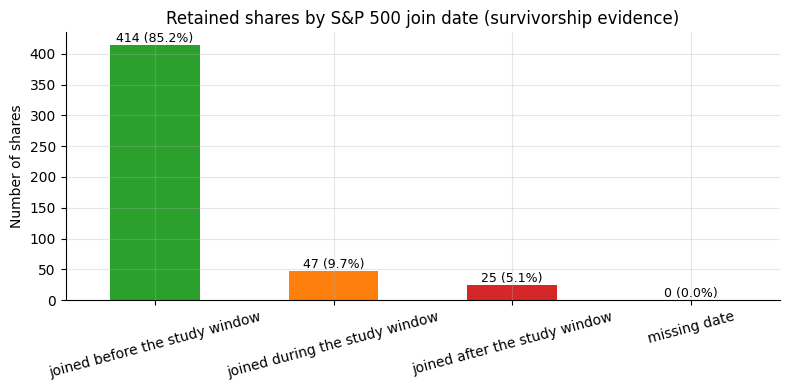

In [29]:
# TASK 1.1 | Part C: survivorship-bias evidence (needs the inclusion log built in Task 1.2 Part A)
# Wikipedia 'Date added' is the date a share joined the S&P 500 (not its listing date). It shows how many retained shares were
# NOT index members for part or all of the study window. Companies removed from the index during 2021-2024 are missing from the data altogether.
added = pd.to_datetime(inclusion_log["Date added"], errors="coerce")
period = pd.Series("missing date", index=inclusion_log.index)
period[added < pd.Timestamp(START)] = "joined before the study window"
period[(added >= pd.Timestamp(START)) & (added < pd.Timestamp(END))] = "joined during the study window"
period[added >= pd.Timestamp(END)] = "joined after the study window"
order = ["joined before the study window", "joined during the study window", "joined after the study window", "missing date"]
counts = period[inclusion_log["included"]].value_counts().reindex(order).fillna(0).astype(int)
print(pd.DataFrame({"retained shares": counts, "percent": (100 * counts / len(included)).round(1)}).to_string())

late = inclusion_log.loc[inclusion_log["included"] & (added >= pd.Timestamp(END)), ["company", "Date added"]].assign(_d=added).sort_values("_d", ascending=False)
print("\nMost recently added retained shares (not index members at any time in the study window):")
print(late.drop(columns="_d").head(10).to_string())
print("\nNote: companies removed from the S&P 500 during the study window are not in today's list, so they are missing from this dataset (not counted).")

ax = counts.plot.bar(figsize=(8, 4), color=["tab:green", "tab:orange", "tab:red", "grey"], title="Retained shares by S&P 500 join date (survivorship evidence)")
for i, v in enumerate(counts):
    ax.text(i, v, f"{v} ({100 * v / len(included):.1f}%)", ha="center", va="bottom", fontsize=9)
plt.ylabel("Number of shares"); plt.xticks(rotation=15)
save_fig("fig04_survivorship_join_dates")

Retained shares with a split-type event: 53 | events: 61
Retained shares paying a dividend: 392 | dividend events: 6024

Events tested by type: {'ordinary split': 44, 'fractional ratio (spin-off style)': 17}
PASSED: no ordinary split has an unadjusted Close
PASSED: no ordinary split has an unadjusted Volume


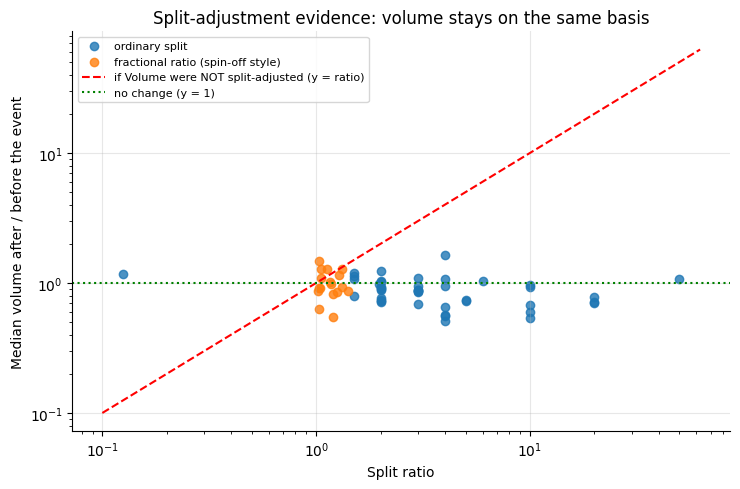

PASSED: Adj Close and Close returns differ only on dividend or split days
PASSED: Adj Close never exceeds Close
Adj Close / Close on the last date (below 1 = later dividends are adjusted into the whole history):
count    486.0000
mean       0.9671
std        0.0286
min        0.8740
25%        0.9490
50%        0.9729
75%        0.9902
max        1.0000

Daily moves beyond +/-40% (ticker, date, return, corporate action that day?): 8
[('BE', '2024-11-15', 0.592, False), ('CVNA', '2022-08-05', 0.401, False), ('CVNA', '2022-12-07', -0.429, False), ('CVNA', '2023-01-12', 0.46, False), ('CVNA', '2023-06-08', 0.56, False), ('CVNA', '2023-07-19', 0.402, False), ('DXCM', '2024-07-26', -0.407, False), ('GL', '2024-04-11', -0.531, False)]
Longest run of unchanged adjusted prices: 2 days | shares with 5 or more: 0
PASSED: no retained share has a frozen price feed (5+ unchanged days in a row)


True

In [30]:
# TASK 1.2 | Part C: corporate actions (splits, spin-off style adjustments, dividends) and price-integrity checks on retained shares
dv, spl = divs[included], splits[included]
print("Retained shares with a split-type event:", int((spl > 0).any().sum()), "| events:", int((spl > 0).sum().sum()))
print("Retained shares paying a dividend:", int((dv > 0).any().sum()), "| dividend events:", int((dv > 0).sum().sum()))

# (1) Are Close and Volume on the same split-adjusted basis? Compare the 20 sessions before and after each event
rows = []
for t in spl.columns[(spl > 0).any()]:
    for d in spl.index[spl[t] > 0]:
        i = trading_days.get_loc(d)
        if i < 5 or n_days - (i + 1) < 5:
            continue                                                   # too close to the edge of the data to test
        before, after = slice(max(i - 20, 0), i), slice(i + 1, min(i + 21, n_days))
        value = c_inc[t] * v_inc[t]
        rows.append({"ticker": t, "date": d, "ratio": float(spl.at[d, t]),
                     "close_ret": float(c_inc[t].iloc[i] / c_inc[t].iloc[i - 1] - 1),
                     "vol_after_before": float(v_inc[t].iloc[after].median() / v_inc[t].iloc[before].median()),
                     "value_after_before": float(value.iloc[after].median() / value.iloc[before].median())})
sp = pd.DataFrame(rows)
if len(sp):
    # ordinary splits (ratio >= 1.5 or <= 0.67) can be tested; fractional ratios (about 1.02-1.4) look like spin-offs and have little test power
    sp["type"] = np.where((sp["ratio"] >= 1.5) | (sp["ratio"] <= 0.67), "ordinary split", "fractional ratio (spin-off style)")
    ordinary = sp["type"] == "ordinary split"
    # If Close were unadjusted, the split-day return would match the raw drop (1/ratio - 1); if Volume were unadjusted, volume after/before would be near the ratio
    sp["close_unadjusted"] = ordinary & ((sp["close_ret"] - (1 / sp["ratio"] - 1)).abs() < 0.10)
    sp["volume_unadjusted"] = ordinary & ((np.log(sp["vol_after_before"]) - np.log(sp["ratio"])).abs() < np.log(sp["vol_after_before"]).abs())
    sp.to_csv(f"{DATA_DIR}/corporate_action_split_check.csv", index=False)
    print("\nEvents tested by type:", sp["type"].value_counts().to_dict())
    check("no ordinary split has an unadjusted Close", sp["close_unadjusted"].sum() == 0, hard=False)
    check("no ordinary split has an unadjusted Volume", sp["volume_unadjusted"].sum() == 0, hard=False)

    fig, ax = plt.subplots(figsize=(7.5, 5))
    for typ, colour in [("ordinary split", "tab:blue"), ("fractional ratio (spin-off style)", "tab:orange")]:
        s = sp[sp["type"] == typ]
        ax.scatter(s["ratio"], s["vol_after_before"], label=typ, color=colour, alpha=0.8)
    xs = np.logspace(np.log10(sp["ratio"].min() * 0.8), np.log10(sp["ratio"].max() * 1.25), 50)
    ax.plot(xs, xs, "r--", label="if Volume were NOT split-adjusted (y = ratio)")
    ax.axhline(1, color="green", ls=":", label="no change (y = 1)")
    ax.set(xscale="log", yscale="log", xlabel="Split ratio", ylabel="Median volume after / before the event",
           title="Split-adjustment evidence: volume stays on the same basis")
    ax.legend(fontsize=8)
    save_fig("fig05_split_adjustment_evidence")

# (2) Do Adj Close and Close differ only on dividend / split days?
r_c, r_a = c_inc.pct_change(fill_method=None), a_inc.pct_change(fill_method=None)
action_day = (dv > 0) | (spl > 0)
unexplained = ((r_a - r_c).abs() > 1e-4) & ~action_day
check("Adj Close and Close returns differ only on dividend or split days", unexplained.sum().sum() == 0, hard=False)
check("Adj Close never exceeds Close", ((a_inc / c_inc) > 1.0001).sum().sum() == 0, hard=False)
print("Adj Close / Close on the last date (below 1 = later dividends are adjusted into the whole history):")
print((a_inc / c_inc).iloc[-1].describe().round(4).to_string())

# (3) Extreme daily moves and frozen prices
ext = r_a.abs() > 0.40
ext_rows = [(t, d.date().isoformat(), round(float(r_a.at[d, t]), 3), bool(action_day.at[d, t])) for t in r_a.columns for d in r_a.index[ext[t]]]
print(f"\nDaily moves beyond +/-40% (ticker, date, return, corporate action that day?): {len(ext_rows)}")
print(ext_rows[:20])

def longest_run(s):
    g = (s != s.shift()).cumsum()
    return int(s.groupby(g).sum().max())

stale = (r_a == 0).apply(longest_run)
print("Longest run of unchanged adjusted prices:", int(stale.max()), "days | shares with 5 or more:", int((stale >= 5).sum()))
check("no retained share has a frozen price feed (5+ unchanged days in a row)", (stale >= 5).sum() == 0, hard=False)

In [31]:
# TASK 1.2 | Part D: Friday-ending weekly prices, incomplete-week exclusion and return-date alignment
# Last available trading-day adjusted close in each Friday-ending week (retained shares and benchmark together)
adj_all = pd.concat([a_inc, panels["adj_close"][BENCH].reindex(trading_days)], axis=1)
check("no missing adjusted prices before resampling", adj_all.notna().all().all())
weekly_px = adj_all.resample("W-FRI").last()

# Independent check: each weekly price equals the adjusted close on that week's final trading day
last_day = trading_days.to_series().groupby(pd.Grouper(freq="W-FRI")).max().dropna()
check_px = adj_all.loc[last_day.values].set_axis(last_day.index)
pd.testing.assert_frame_equal(check_px.loc[weekly_px.index], weekly_px, check_names=False, check_freq=False)
print("PASSED: weekly prices equal the final trading-day adjusted close of each week")

# Exclude incomplete first/last calendar weeks: the week's Monday must be on or after the start, its Friday label not after the last data date
labels = weekly_px.index
is_complete = ((labels - pd.Timedelta(days=4)) >= pd.Timestamp(START)) & (labels <= trading_days[-1])
print("Weekly labels dropped as incomplete calendar weeks:", [d.date().isoformat() for d in labels[~is_complete]])
weekly_px = weekly_px.loc[is_complete]

# Holiday-shortened weeks are retained
sessions_per_week = trading_days.to_series().resample("W-FRI").count().reindex(weekly_px.index)
print(f"Holiday-shortened weeks retained (fewer than 5 sessions): {int((sessions_per_week < 5).sum())} | sessions per week: {sessions_per_week.value_counts().sort_index().to_dict()}")
check("Good Friday 2021 week uses Thursday's close",
      np.isclose(weekly_px.loc[pd.Timestamp("2021-04-02"), BENCH], adj_all.loc[pd.Timestamp("2021-04-01"), BENCH]), hard=False)

# Weekly return = this week's adjusted close / previous week's adjusted close - 1 (no filling, no multi-week returns)
check("weekly prices: no gaps, Fridays only, unique labels", weekly_px.notna().all().all() and (weekly_px.index.dayofweek == 4).all() and weekly_px.index.is_unique)
check("consecutive weeks: no week skipped", (weekly_px.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all())
weekly_ret = weekly_px.pct_change(fill_method=None).iloc[1:]
check("weekly returns complete (no missing values)", weekly_ret.notna().all().all())
check("shares and benchmark share identical week labels", weekly_ret.index.equals(weekly_px.index[1:]))
t0 = included[0]
check("weekly return formula matches a manual calculation", np.allclose(weekly_px[t0].iloc[1:].values / weekly_px[t0].iloc[:-1].values - 1, weekly_ret[t0].values))

N_WEEKS = len(weekly_ret)
print(f"\nWeekly price labels: {len(weekly_px)} | aligned weekly return observations: {N_WEEKS}")
print(f"First return week: {weekly_ret.index[0].date()} | last return week: {weekly_ret.index[-1].date()} | shares x weeks: {weekly_ret[included].shape}")
weekly_px.to_csv(f"{DATA_DIR}/weekly_adj_close.csv")
weekly_ret.to_csv(f"{DATA_DIR}/weekly_returns.csv")

PASSED: no missing adjusted prices before resampling
PASSED: weekly prices equal the final trading-day adjusted close of each week
Weekly labels dropped as incomplete calendar weeks: ['2025-01-03']
Holiday-shortened weeks retained (fewer than 5 sessions): 37 | sessions per week: {4: 37, 5: 171}
PASSED: Good Friday 2021 week uses Thursday's close
PASSED: weekly prices: no gaps, Fridays only, unique labels
PASSED: consecutive weeks: no week skipped
PASSED: weekly returns complete (no missing values)
PASSED: shares and benchmark share identical week labels
PASSED: weekly return formula matches a manual calculation

Weekly price labels: 208 | aligned weekly return observations: 207
First return week: 2021-01-15 | last return week: 2024-12-27 | shares x weeks: (207, 486)


## Task 1.3 - Weekly return and weekly beta

In [32]:
# TASK 1.3.1 | Mean weekly return per share (arithmetic mean of the Friday-ending weekly returns)
share_ret, bench_ret = weekly_ret[included], weekly_ret[BENCH]
mean_ret = share_ret.mean().rename("mean_weekly_return")
px = weekly_px[included].to_numpy()
check("mean weekly return equals an independent numpy recalculation", np.allclose(mean_ret.to_numpy(), (px[1:] / px[:-1] - 1).mean(axis=0)))
check("every share has the same number of weekly observations", share_ret.count().nunique() == 1 and share_ret.count().iloc[0] == N_WEEKS)

# Worked example for one share
ex = "AAPL" if "AAPL" in included else included[0]
w = weekly_px[ex]
print(f"Worked example: {ex}")
print(pd.DataFrame({"week_end": w.index[:4].date, "adj_close": w.iloc[:4].round(4).values,
                    "weekly_return": w.pct_change(fill_method=None).iloc[:4].round(5).values}).to_string(index=False))
print(f"Mean of the {N_WEEKS} weekly returns = {mean_ret[ex]:.5f} ({100 * mean_ret[ex]:.3f}% per week); the first week has no previous week, so it has no return\n")

print((100 * mean_ret).describe().round(3).rename("mean weekly return, % per week").to_string())
print("Skewness:", round(float(mean_ret.skew()), 3), "| excess kurtosis:", round(float(mean_ret.kurt()), 3))
print("Benchmark (^GSPC) mean weekly return:", round(100 * float(bench_ret.mean()), 3), "% per week")
names = inclusion_log["company"]
print("\nHighest:", [(t, names[t], round(float(100 * mean_ret[t]), 3)) for t in mean_ret.nlargest(5).index])
print("Lowest: ", [(t, names[t], round(float(100 * mean_ret[t]), 3)) for t in mean_ret.nsmallest(5).index])

# Limit of the arithmetic mean: it can never be below the compound (geometric) weekly growth rate, and the gap grows with volatility
geo = (weekly_px[included].iloc[-1] / weekly_px[included].iloc[0]) ** (1 / N_WEEKS) - 1
gap = mean_ret - geo
check("arithmetic mean is never below the geometric mean", (gap > -1e-10).all())
print("Arithmetic minus geometric weekly mean (percentage points): median", round(100 * float(gap.median()), 3), "| max", round(100 * float(gap.max()), 3),
      "| correlation with half the weekly variance:", round(float(np.corrcoef(gap, share_ret.var() / 2)[0, 1]), 3))

PASSED: mean weekly return equals an independent numpy recalculation
PASSED: every share has the same number of weekly observations
Worked example: AAPL
  week_end  adj_close  weekly_return
2021-01-08   128.0981            NaN
2021-01-15   123.3351       -0.03718
2021-01-22   134.9080        0.09383
2021-01-29   128.0108       -0.05113
Mean of the 207 weekly returns = 0.00393 (0.393% per week); the first week has no previous week, so it has no return

count    486.000
mean       0.286
std        0.265
min       -0.447
25%        0.118
50%        0.262
75%        0.421
max        1.777
Skewness: 0.868 | excess kurtosis: 3.019
Benchmark (^GSPC) mean weekly return: 0.24 % per week

Highest: [('SMCI', 'Supermicro', 1.777), ('NVDA', 'Nvidia', 1.362), ('VRT', 'Vertiv', 1.258), ('VST', 'Vistra Corp.', 1.139), ('FIX', 'Comfort Systems USA', 1.13)]
Lowest:  [('EL', 'Estée Lauder Companies (The)', -0.447), ('BAX', 'Baxter International', -0.38), ('DG', 'Dollar General', -0.352), ('PYPL', 'PayPal

In [33]:
# TASK 1.3.2 | Weekly beta per share = covariance(share, benchmark) / variance(benchmark), full period
check("aligned weekly observations: identical labels, no gaps",
      share_ret.index.equals(bench_ret.index) and share_ret.notna().all().all() and bench_ret.notna().all())
n = len(bench_ret)
print(f"Aligned weekly observations used for every beta: {n} ({bench_ret.index[0].date()} to {bench_ret.index[-1].date()})")

beta = (share_ret.apply(lambda s: s.cov(bench_ret)) / bench_ret.var()).rename("weekly_beta")      # sample covariance / sample variance
x, Y = bench_ret.to_numpy(), share_ret.to_numpy()
check("beta equals the numpy covariance formula",
      np.allclose(beta.to_numpy(), np.array([np.cov(Y[:, j], x)[0, 1] for j in range(Y.shape[1])]) / np.var(x, ddof=1)))
check("beta equals a fitted regression slope", np.allclose(beta.to_numpy(), [np.polyfit(x, Y[:, j], 1)[0] for j in range(Y.shape[1])]))
check("the benchmark's own beta equals 1", np.isclose(bench_ret.cov(bench_ret) / bench_ret.var(), 1.0))
check("benchmark Adj Close equals Close (a price index has no dividends)",
      np.allclose(panels["adj_close"][BENCH].dropna(), panels["close"][BENCH].dropna()), hard=False)

ex = "AAPL" if "AAPL" in included else included[0]
print(f"\nWorked example: {ex} | cov(share, benchmark) = {share_ret[ex].cov(bench_ret):.6f} | var(benchmark) = {bench_ret.var():.6f} | beta = {beta[ex]:.3f}")
print("\nWeekly beta summary:")
print(beta.describe().round(3).to_string())
print("Skewness:", round(float(beta.skew()), 3), "| excess kurtosis:", round(float(beta.kurt()), 3))
print("Share with beta > 1:", round(float((beta > 1).mean()), 3), "| beta < 0.5:", int((beta < 0.5).sum()), "| beta < 0:", int((beta < 0).sum()))
print("Highest:", [(t, names[t], round(float(beta[t]), 3)) for t in beta.nlargest(5).index])
print("Lowest: ", [(t, names[t], round(float(beta[t]), 3)) for t in beta.nsmallest(5).index])

# Estimation limits: explanatory power, precision (standard error) and stability between the two halves of the period
r = share_ret.corrwith(bench_ret)
se = beta.abs() * np.sqrt((1 - r ** 2) / (r ** 2 * (n - 2)))
print(f"\nCorrelation with the benchmark: median {r.median():.3f} | R-squared: median {(r ** 2).median():.3f}")
print(f"Standard error of beta: median {se.median():.3f} | max {se.max():.3f} | share of betas whose 95% interval contains 1: {((beta - 1).abs() < 1.96 * se).mean():.3f}")
h = n // 2
b1 = share_ret.iloc[:h].apply(lambda s: s.cov(bench_ret.iloc[:h])) / bench_ret.iloc[:h].var()
b2 = share_ret.iloc[h:].apply(lambda s: s.cov(bench_ret.iloc[h:])) / bench_ret.iloc[h:].var()
print(f"Beta in the first {h} weeks versus the last {n - h} weeks: correlation {b1.corr(b2):.3f} | median absolute change {(b2 - b1).abs().median():.3f}")

feat = pd.DataFrame({"n_weekly_obs": share_ret.count(), "mean_weekly_return": mean_ret, "weekly_beta": beta})
feat.to_csv(f"{DATA_DIR}/features_return_beta.csv")

PASSED: aligned weekly observations: identical labels, no gaps
Aligned weekly observations used for every beta: 207 (2021-01-15 to 2024-12-27)
PASSED: beta equals the numpy covariance formula
PASSED: beta equals a fitted regression slope
PASSED: the benchmark's own beta equals 1
PASSED: benchmark Adj Close equals Close (a price index has no dividends)

Worked example: AAPL | cov(share, benchmark) = 0.000578 | var(benchmark) = 0.000492 | beta = 1.175

Weekly beta summary:
count    486.000
mean       0.974
std        0.407
min        0.055
25%        0.667
50%        0.951
75%        1.180
max        3.779
Skewness: 1.104 | excess kurtosis: 4.471
Share with beta > 1: 0.444 | beta < 0.5: 59 | beta < 0: 0
Highest: [('CVNA', 'Carvana', 3.779), ('XYZ', 'Block, Inc.', 2.505), ('COHR', 'Coherent Corp.', 2.139), ('NVDA', 'Nvidia', 2.126), ('TWLO', 'Twilio', 2.073)]
Lowest:  [('GIS', 'General Mills', 0.055), ('SJM', 'J.M. Smucker Company (The)', 0.176), ('MRK', 'Merck & Co.', 0.198), ('BMY', 'Br

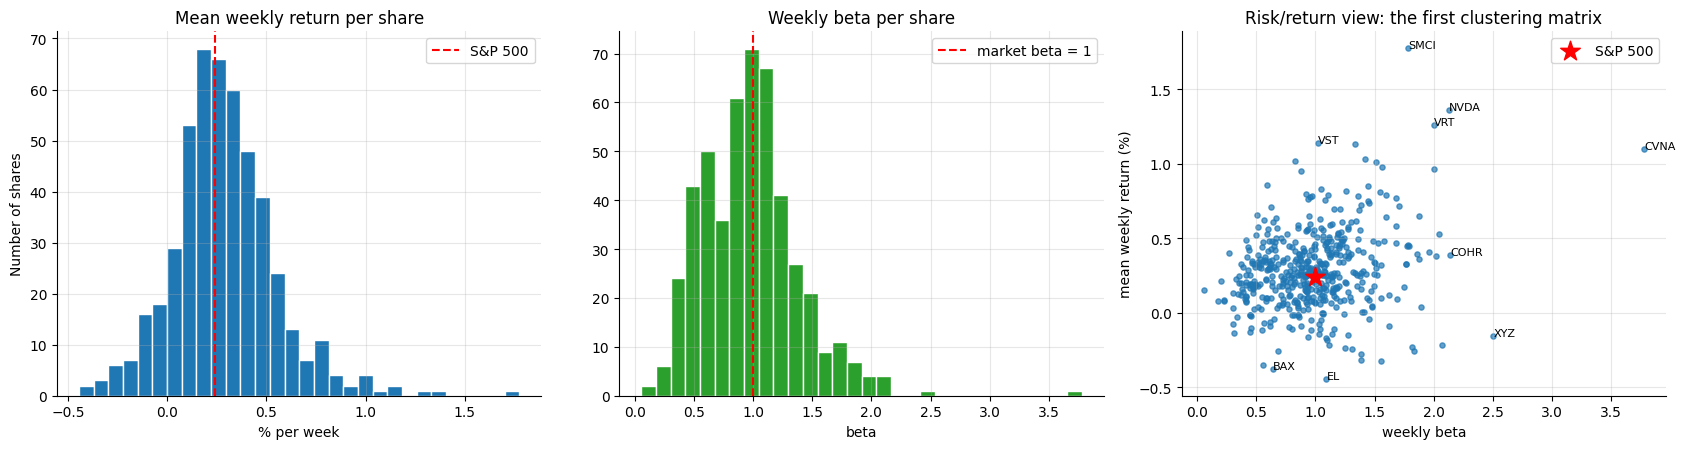

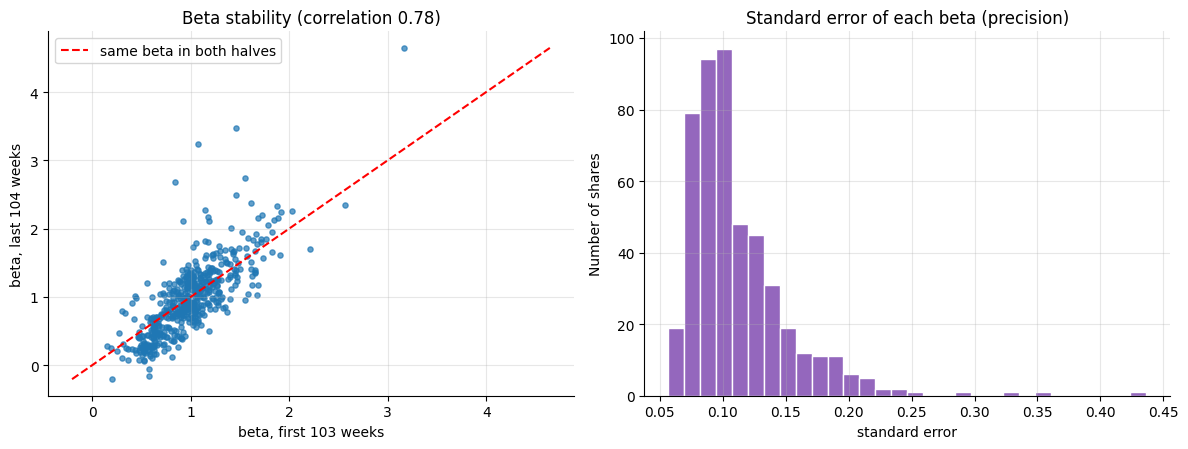

In [34]:
# TASK 1.3 | Part C: diagrams - the risk/return view and the limits of beta
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].hist(100 * mean_ret, bins=30, color="tab:blue", edgecolor="white")
ax[0].axvline(100 * bench_ret.mean(), color="red", ls="--", label="S&P 500")
ax[0].set(title="Mean weekly return per share", xlabel="% per week", ylabel="Number of shares"); ax[0].legend()
ax[1].hist(beta, bins=30, color="tab:green", edgecolor="white")
ax[1].axvline(1, color="red", ls="--", label="market beta = 1")
ax[1].set(title="Weekly beta per share", xlabel="beta"); ax[1].legend()
ax[2].scatter(beta, 100 * mean_ret, s=14, alpha=0.7)
ax[2].scatter([1], [100 * bench_ret.mean()], color="red", marker="*", s=220, label="S&P 500", zorder=3)
for t in set(mean_ret.nlargest(4).index) | set(beta.nlargest(4).index) | set(mean_ret.nsmallest(2).index):
    ax[2].annotate(t, (beta[t], 100 * mean_ret[t]), fontsize=8)
ax[2].set(title="Risk/return view: the first clustering matrix", xlabel="weekly beta", ylabel="mean weekly return (%)"); ax[2].legend()
save_fig("fig06_return_and_beta")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(b1, b2, s=14, alpha=0.7)
lim = [min(b1.min(), b2.min()), max(b1.max(), b2.max())]
ax[0].plot(lim, lim, "r--", label="same beta in both halves")
ax[0].set(title=f"Beta stability (correlation {b1.corr(b2):.2f})", xlabel=f"beta, first {h} weeks", ylabel=f"beta, last {n - h} weeks"); ax[0].legend()
ax[1].hist(se, bins=30, color="tab:purple", edgecolor="white")
ax[1].set(title="Standard error of each beta (precision)", xlabel="standard error", ylabel="Number of shares")
save_fig("fig07_beta_stability_and_precision")

PASSED: no missing Close values for the experiment
PASSED: Close-based weekly returns use exactly the same weeks
Mean weekly return, Adj Close basis minus Close basis (percentage points per week):
   dividend payers: median 0.0407, max 0.1516 (n=392)
   non-payers     : max absolute difference 0.000000 (n=94)
Correlation of mean return across the two bases: 0.994
Weekly beta: correlation 0.9999 | Spearman 0.9999 | absolute difference median 0.0013 max 0.0171 | shares moving by more than 0.05: 0


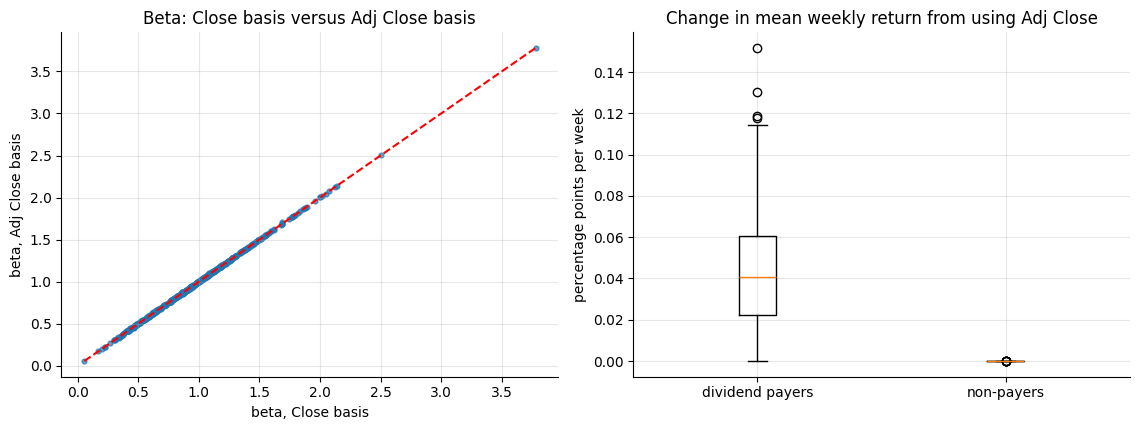

In [35]:
# EXPERIMENT A (supports TASK 1.3) | Price-basis sensitivity: Close (price return) versus Adj Close (dividend-adjusted)
# The benchmark is a price index; the shares' Adj Close includes dividends. How much does that choice change the two features?
c_all = panels["close"].reindex(trading_days)[included + [BENCH]]
check("no missing Close values for the experiment", c_all.notna().all().all())
ret_close = c_all.resample("W-FRI").last().loc[weekly_px.index].pct_change(fill_method=None).iloc[1:]
check("Close-based weekly returns use exactly the same weeks", ret_close.index.equals(weekly_ret.index))

mean_close = ret_close[included].mean()
beta_close = ret_close[included].apply(lambda s: s.cov(ret_close[BENCH])) / ret_close[BENCH].var()
pays = (dv > 0).any().reindex(included)                  # paid a dividend inside the study window
d_mean = 100 * (mean_ret - mean_close)                   # percentage points per week
d_beta = (beta - beta_close).abs()
print("Mean weekly return, Adj Close basis minus Close basis (percentage points per week):")
print("   dividend payers:", f"median {d_mean[pays].median():.4f}, max {d_mean[pays].max():.4f} (n={int(pays.sum())})")
print("   non-payers     :", f"max absolute difference {d_mean[~pays].abs().max():.6f} (n={int((~pays).sum())})")
print("Correlation of mean return across the two bases:", round(float(mean_ret.corr(mean_close)), 4))
print("Weekly beta: correlation", round(float(beta.corr(beta_close)), 4), "| Spearman", round(float(beta.rank().corr(beta_close.rank())), 4),
      "| absolute difference median", round(float(d_beta.median()), 4), "max", round(float(d_beta.max()), 4),
      "| shares moving by more than 0.05:", int((d_beta > 0.05).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax[0].scatter(beta_close, beta, s=12, alpha=0.7)
lim = [beta.min(), beta.max()]
ax[0].plot(lim, lim, "r--")
ax[0].set(title="Beta: Close basis versus Adj Close basis", xlabel="beta, Close basis", ylabel="beta, Adj Close basis")
ax[1].boxplot([d_mean[pays], d_mean[~pays]])
ax[1].set_xticklabels(["dividend payers", "non-payers"])
ax[1].set(title="Change in mean weekly return from using Adj Close", ylabel="percentage points per week")
save_fig("fig08_experiment_a_price_basis")

## Task 1.4 - Adapted RFM (Recency, Frequency, Monetary) for share trading activity

In [36]:
# TASK 1.4 | Part A: the event rule and the R / F / M helper functions, each tested on toy data
def high_volume_flags(volume, window=20, mult=2.0):
    baseline = volume.rolling(window).mean().shift(1)       # mean of the PRECEDING 20 sessions: shift(1) excludes the day being tested
    threshold = mult * baseline                              # calculated separately for every share and every day
    flags = (volume > threshold) & threshold.notna()         # strictly greater than twice the baseline; no baseline = not an event
    return baseline, threshold, flags

def latest_event_days(flag_frame, obs_date):
    """Recency: calendar days from the latest qualifying day on or before obs_date to obs_date (NaN if none, never 0)."""
    f = flag_frame.loc[:obs_date]
    last = pd.to_datetime(f.where(f).apply(lambda s: s.last_valid_index()))
    return (obs_date - last).dt.days

def rfm_at(obs_date):
    """R, F and M for any observation date; F and M use the 60 sessions ending on that date (needs flags, c_inc, v_inc)."""
    pos = trading_days.get_loc(obs_date)
    assert pos >= 59, "fewer than 60 sessions available"
    win = trading_days[pos - 59: pos + 1]
    return pd.DataFrame({"recency_days": latest_event_days(flags, obs_date),
                         "frequency_60d": flags.loc[win].sum(),
                         "monetary_usd": (c_inc * v_inc).loc[win].sum()})

# Event rule: the brief's own example (baseline 1 million -> threshold 2 million)
def toy_flag(last_day):
    return bool(high_volume_flags(pd.Series([1_000_000.0] * 20 + [last_day]))[2].iloc[-1])

check("event rule: 2.5 million against a 1 million baseline qualifies", toy_flag(2_500_000.0) is True)
check("event rule: 1.8 million does not qualify", toy_flag(1_800_000.0) is False)
check("event rule: exactly twice the baseline does not qualify (strictly greater)", toy_flag(2_000_000.0) is False)
check("event rule: just above twice the baseline qualifies", toy_flag(2_000_001.0) is True)
check("event rule: no event without 20 prior sessions", not high_volume_flags(pd.Series([1e6] * 4 + [9e6] + [1e6] * 20))[2].iloc[:20].any())
check("event rule: a day's own volume does not lift its own threshold", high_volume_flags(pd.Series([1e6] * 20 + [2_100_000.0]))[1].iloc[-1] == 2_000_000.0)

# Recency: same day = 0, weekends counted, no event = missing
toy_days = pd.date_range("2024-09-02", "2024-09-20", freq="B")
toy = pd.DataFrame(False, index=toy_days, columns=["same_day", "two_days_ago", "friday_event", "no_event"])
toy.loc[pd.Timestamp("2024-09-20"), "same_day"] = True
toy.loc[pd.Timestamp("2024-09-18"), "two_days_ago"] = True
toy.loc[pd.Timestamp("2024-09-13"), "friday_event"] = True
toy_r = latest_event_days(toy, pd.Timestamp("2024-09-20"))
check("Recency: event on the observation date gives 0; two days earlier gives 2", toy_r["same_day"] == 0 and toy_r["two_days_ago"] == 2)
check("Recency: Friday 13 Sept to Friday 20 Sept is 7 calendar days", toy_r["friday_event"] == 7)
check("Recency: Friday to the next Monday is 3 calendar days (weekend counted)", latest_event_days(toy, pd.Timestamp("2024-09-16"))["friday_event"] == 3)
check("Recency: no event gives a missing value, not zero", np.isnan(toy_r["no_event"]))

# Frequency: seven events = 7; first window day counts; the day before the window does not
tf = pd.DataFrame(False, index=pd.date_range("2024-01-01", periods=80, freq="B"), columns=["seven", "edge_in", "edge_out"])
tw = tf.index[-60:]
tf.loc[tw[[0, 5, 12, 20, 31, 44, 59]], "seven"] = True
tf.loc[tw[0], "edge_in"] = True
tf.loc[tf.index[-61], "edge_out"] = True
tfs = tf.loc[tw].sum()
check("Frequency: seven qualifying days give 7; first window day counts; the day before the window does not",
      tfs["seven"] == 7 and tfs["edge_in"] == 1 and tfs["edge_out"] == 0)

# Monetary: $100 x 2 million shares = $200 million a day; 60 such days = $12 billion
check("Monetary: the brief's example ($100 x 2 million = $200 million a day; 60 days = $12 billion)",
      100.0 * 2_000_000.0 == 200_000_000.0 and sum([100.0 * 2_000_000.0] * 60) == 12_000_000_000.0)

PASSED: event rule: 2.5 million against a 1 million baseline qualifies
PASSED: event rule: 1.8 million does not qualify
PASSED: event rule: exactly twice the baseline does not qualify (strictly greater)
PASSED: event rule: just above twice the baseline qualifies
PASSED: event rule: no event without 20 prior sessions
PASSED: event rule: a day's own volume does not lift its own threshold
PASSED: Recency: event on the observation date gives 0; two days earlier gives 2
PASSED: Recency: Friday 13 Sept to Friday 20 Sept is 7 calendar days
PASSED: Recency: Friday to the next Monday is 3 calendar days (weekend counted)
PASSED: Recency: no event gives a missing value, not zero
PASSED: Frequency: seven qualifying days give 7; first window day counts; the day before the window does not
PASSED: Monetary: the brief's example ($100 x 2 million = $200 million a day; 60 days = $12 billion)


True

In [37]:
# TASK 1.4 | Part B: event flags, then Recency, Frequency and Monetary for every retained share
baseline, threshold, flags = high_volume_flags(v_inc)
altered = v_inc.copy()
altered.iloc[600:] = altered.iloc[600:] * 10
check("no look-ahead: changing later volumes changes no earlier flag", flags.iloc[:600].equals(high_volume_flags(altered)[2].iloc[:600]))
WIN = trading_days[-60:]
check("the 60-session window ends on the observation date", WIN[-1] == OBS_DATE and len(WIN) == 60)
check("every share has a valid 20-session baseline on all 60 window days", threshold.loc[WIN].notna().all().all())
print(f"Observation date: {OBS_DATE.date()} | 60-session window: {WIN[0].date()} to {WIN[-1].date()} | first testable day for the baseline: {trading_days[20].date()}")
flags.astype(int).to_csv(f"{DATA_DIR}/high_volume_flags.csv")

testable, n_events = int(threshold.notna().sum().sum()), flags.sum()
print(f"\nHigh-volume days flagged: {int(n_events.sum())} of {testable} testable share-days ({100 * n_events.sum() / testable:.2f}%)")
print("Events per share over the full history: median", int(n_events.median()), "| min", int(n_events.min()), "| max", int(n_events.max()))

rfm = rfm_at(OBS_DATE)
recency, frequency, monetary = rfm["recency_days"], rfm["frequency_60d"], rfm["monetary_usd"]

# Independent recalculations
for t in included:                                                       # Recency by a plain loop
    d = flags.index[flags[t].values]
    expected = (OBS_DATE - d.max()).days if len(d) else np.nan
    assert (np.isnan(expected) and np.isnan(recency[t])) or expected == recency[t]
print("PASSED: Recency matches an independent loop recalculation for every share")
V = v_inc.to_numpy()
manual_f = np.zeros(V.shape[1], dtype=int)
for d in WIN:                                                            # Frequency straight from raw volumes, explicit 20-session baseline
    i = trading_days.get_loc(d)
    manual_f += (V[i] > 2 * V[i - 20:i].mean(axis=0))
check("Frequency matches an independent recalculation from raw volumes", (manual_f == frequency.to_numpy()).all())
check("Monetary matches an independent positional recalculation",
      np.allclose(monetary.to_numpy(), (c_inc.to_numpy()[-60:] * v_inc.to_numpy()[-60:]).sum(axis=0)))
span = (OBS_DATE - WIN[0]).days
has_r = recency.notna()
check(f"Frequency > 0 exactly when the latest event lies inside the window (span {span} days)",
      ((frequency[has_r] > 0) == (recency[has_r] <= span)).all())
F61 = flags.loc[trading_days[-61:]].sum()
print("Shares whose Frequency would change with a 61-session window (boundary matters):", int((F61 != frequency).sum()))

# No-event handling: a share with no event gets a missing Recency and is excluded from RFM clustering (never given 0)
no_event = recency.index[recency.isna()].tolist()
print(f"Shares with no event in the valid history (Recency missing, excluded from RFM clustering): {len(no_event)} {no_event}")
print("Shares with an event ON the observation date (R = 0):", int((recency == 0).sum()))

# Summaries
print("\nRecency (calendar days):")
print(recency.describe().round(1).to_string())
mode_r = recency.mode().iloc[0]
print(f"Skewness {recency.skew():.3f} | most common value {mode_r:.0f} days, shared by {int((recency == mode_r).sum())} shares ({100 * (recency == mode_r).mean():.1f}%)")
print("\nFrequency (high-volume days in the window):")
print(frequency.describe().round(2).to_string())
print("Skewness", round(float(frequency.skew()), 3), "| distribution (F: shares):", frequency.value_counts().sort_index().to_dict())
print("\nMonetary (USD billions):")
print((monetary / 1e9).describe().round(2).to_string())
print("Skewness raw:", round(float(monetary.skew()), 3), "| after log1p:", round(float(np.log1p(monetary).skew()), 3))
print("Highest:", [(t, names[t], round(float(monetary[t] / 1e9), 1)) for t in monetary.nlargest(5).index])
print("Lowest: ", [(t, names[t], round(float(monetary[t] / 1e9), 2)) for t in monetary.nsmallest(5).index])

# Why Close and not Adj Close for Monetary
ratio = (a_inc * v_inc).loc[WIN].sum() / monetary
print(f"\nIf Adj Close were used for Monetary, traded value would be understated by a median of {100 * (1 - ratio.median()):.1f}% (up to {100 * (1 - ratio.min()):.1f}%)")

PASSED: no look-ahead: changing later volumes changes no earlier flag
PASSED: the 60-session window ends on the observation date
PASSED: every share has a valid 20-session baseline on all 60 window days
Observation date: 2024-12-31 | 60-session window: 2024-10-07 to 2024-12-31 | first testable day for the baseline: 2021-02-02

High-volume days flagged: 18280 of 478710 testable share-days (3.82%)
Events per share over the full history: median 37 | min 15 | max 75
PASSED: Recency matches an independent loop recalculation for every share
PASSED: Frequency matches an independent recalculation from raw volumes
PASSED: Monetary matches an independent positional recalculation
PASSED: Frequency > 0 exactly when the latest event lies inside the window (span 85 days)
Shares whose Frequency would change with a 61-session window (boundary matters): 2
Shares with no event in the valid history (Recency missing, excluded from RFM clustering): 0 []
Shares with an event ON the observation date (R = 0):

Days with the highest share of shares flagged:
              weekday  % of shares flagged
Date                                      
2024-12-20     Friday                 72.8
2023-12-15     Friday                 65.6
2024-09-20     Friday                 63.8
2022-12-16     Friday                 58.2
2021-09-17     Friday                 57.0
2021-11-30    Tuesday                 52.7
2022-09-16     Friday                 50.2
2023-09-15     Friday                 49.2
2023-03-17     Friday                 46.9
2023-05-31  Wednesday                 44.2

Median daily breadth: 2.1% | days with more than 30% of shares flagged: 18 of 1005
Share of ALL flagged share-days that fall on those market-wide days: 23.4%
Share of the window's events that fall on 2024-12-20: 24.4%


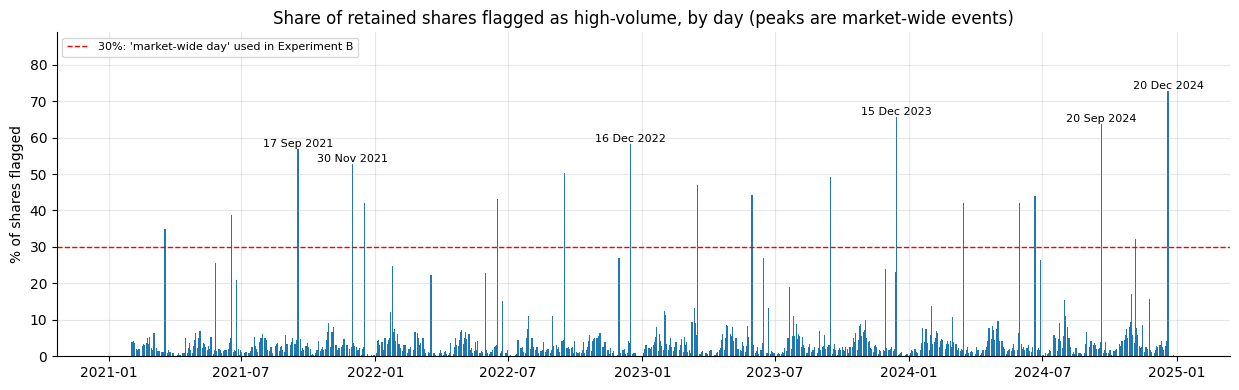

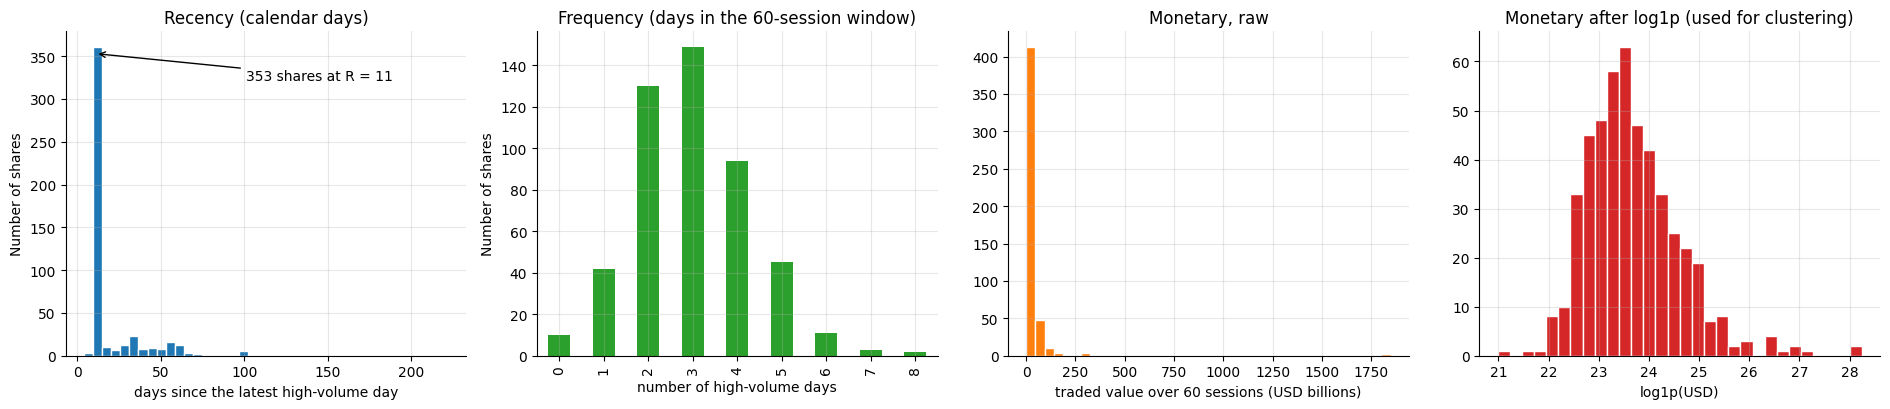

In [38]:
# TASK 1.4 | Part C: diagrams - how market-wide are the high-volume days, and what do R, F and M look like?
breadth = flags.mean(axis=1)                    # share of retained shares flagged on each day
top = breadth.nlargest(10)
print("Days with the highest share of shares flagged:")
print(pd.DataFrame({"weekday": top.index.day_name(), "% of shares flagged": (100 * top).round(1)}).to_string())
wide = breadth > 0.30
print(f"\nMedian daily breadth: {100 * breadth.median():.1f}% | days with more than 30% of shares flagged: {int(wide.sum())} of {n_days}")
print(f"Share of ALL flagged share-days that fall on those market-wide days: {100 * flags.loc[wide].sum().sum() / flags.sum().sum():.1f}%")
print(f"Share of the window's events that fall on {breadth.loc[WIN].idxmax().date()}: {100 * flags.loc[breadth.loc[WIN].idxmax()].sum() / frequency.sum():.1f}%")

fig, ax = plt.subplots(figsize=(12.5, 4))
ax.bar(breadth.index, 100 * breadth, width=1.6, color="tab:blue")
ax.axhline(30, color="red", ls="--", lw=1, label="30%: 'market-wide day' used in Experiment B")
for d, v in breadth.nlargest(6).items():
    ax.annotate(d.strftime("%d %b %Y"), (d, 100 * v), fontsize=8, ha="center", va="bottom")
ax.set(title="Share of retained shares flagged as high-volume, by day (peaks are market-wide events)", ylabel="% of shares flagged")
ax.set_ylim(0, 100 * breadth.max() * 1.22)
ax.legend(loc="upper left", fontsize=8)
save_fig("fig09_event_breadth")

fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
ax[0].hist(recency, bins=40, color="tab:blue", edgecolor="white")
ax[0].set(title="Recency (calendar days)", xlabel="days since the latest high-volume day", ylabel="Number of shares")
ax[0].annotate(f"{int((recency == mode_r).sum())} shares at R = {mode_r:.0f}", (mode_r, (recency == mode_r).sum() / 1.0), xytext=(0.45, 0.85),
               textcoords="axes fraction", arrowprops=dict(arrowstyle="->"))
frequency.value_counts().sort_index().plot.bar(ax=ax[1], color="tab:green")
ax[1].set(title="Frequency (days in the 60-session window)", xlabel="number of high-volume days", ylabel="Number of shares")
ax[2].hist(monetary / 1e9, bins=40, color="tab:orange", edgecolor="white")
ax[2].set(title="Monetary, raw", xlabel="traded value over 60 sessions (USD billions)")
ax[3].hist(np.log1p(monetary), bins=30, color="tab:red", edgecolor="white")
ax[3].set(title="Monetary after log1p (used for clustering)", xlabel="log1p(USD)")
save_fig("fig10_rfm_distributions")

Experiment B: market-wide days ignored: 18 of 1005
   shares whose Recency changes: 369 of 486 | shares with no share-specific event at all: 0
   Recency baseline: median 11.0 std 21.3 | market-adjusted: median 50.0 std 44.4
   Frequency baseline mean 2.99 | market-adjusted mean 1.94 | correlation of Frequency across the two versions 0.88


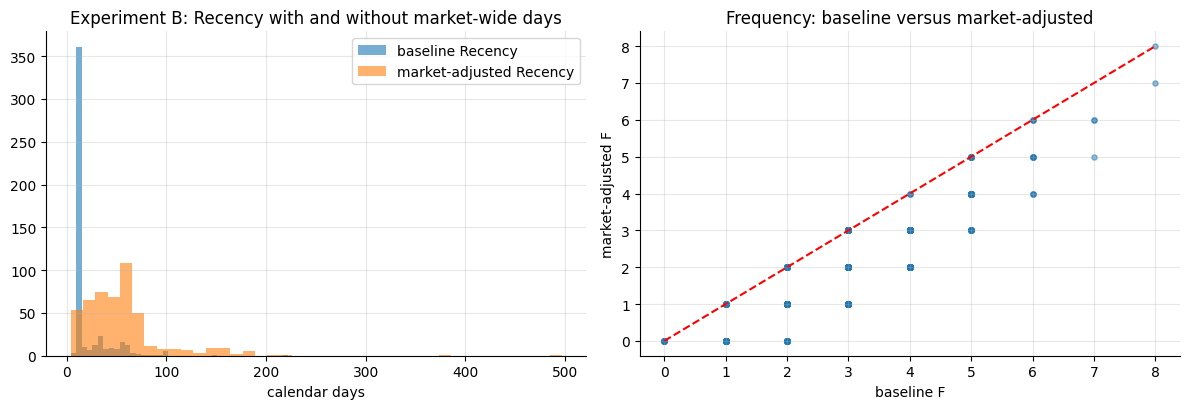


Experiment C: RFM at other observation dates
observation_date  most_common_R  pct_shares_at_that_R  median_R  mean_F  shares_with_F_zero  median_M_usd_bn
      2024-09-30             10                  59.3      10.0    2.46                  17             15.5
      2024-10-31             41                  23.0      15.0    2.22                  23             14.8
      2024-11-29             23                  20.2      23.0    2.94                  12             16.3
      2024-12-31             11                  72.6      11.0    2.99                  10             16.7


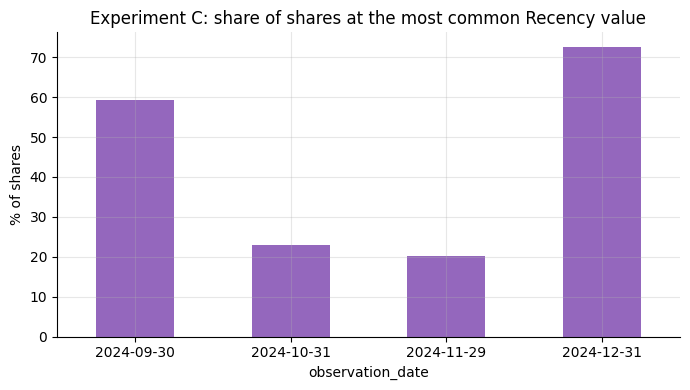

In [39]:
# EXPERIMENT B and C (extensions, clearly separate from the baseline RFM)
# Experiment B: market-adjusted activity. Ignore market-wide days (more than 30% of shares flagged) when finding events
wide_days = breadth.index[breadth > 0.30]
flags_idio = flags.copy()
flags_idio.loc[wide_days] = False
recency_idio = latest_event_days(flags_idio, OBS_DATE)
frequency_idio = flags_idio.loc[WIN].sum()
print(f"Experiment B: market-wide days ignored: {len(wide_days)} of {n_days}")
print("   shares whose Recency changes:", int((recency_idio != recency).sum()), "of", len(included),
      "| shares with no share-specific event at all:", int(recency_idio.isna().sum()))
print("   Recency baseline: median", recency.median(), "std", round(float(recency.std()), 1),
      "| market-adjusted: median", recency_idio.median(), "std", round(float(recency_idio.std()), 1))
print("   Frequency baseline mean", round(float(frequency.mean()), 2), "| market-adjusted mean", round(float(frequency_idio.mean()), 2),
      "| correlation of Frequency across the two versions", round(float(frequency.corr(frequency_idio)), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(recency, bins=40, alpha=0.6, label="baseline Recency", color="tab:blue")
ax[0].hist(recency_idio.dropna(), bins=40, alpha=0.6, label="market-adjusted Recency", color="tab:orange")
ax[0].set(title="Experiment B: Recency with and without market-wide days", xlabel="calendar days"); ax[0].legend()
ax[1].scatter(frequency, frequency_idio, s=14, alpha=0.5)
ax[1].plot([0, frequency.max()], [0, frequency.max()], "r--")
ax[1].set(title="Frequency: baseline versus market-adjusted", xlabel="baseline F", ylabel="market-adjusted F")
save_fig("fig11_experiment_b_market_adjusted")

# Experiment C: observation-date sensitivity (how much does the picture depend on where the observation date falls?)
rows = []
for m in ["2024-09-30", "2024-10-31", "2024-11-29", "2024-12-31"]:
    d = trading_days[trading_days <= pd.Timestamp(m)][-1]
    r_d = rfm_at(d)
    modal = r_d["recency_days"].mode().iloc[0]
    rows.append({"observation_date": d.date().isoformat(), "most_common_R": modal,
                 "pct_shares_at_that_R": round(100 * (r_d["recency_days"] == modal).mean(), 1),
                 "median_R": r_d["recency_days"].median(), "mean_F": round(float(r_d["frequency_60d"].mean()), 2),
                 "shares_with_F_zero": int((r_d["frequency_60d"] == 0).sum()), "median_M_usd_bn": round(float(r_d["monetary_usd"].median() / 1e9), 1)})
obs_sens = pd.DataFrame(rows)
obs_sens.to_csv(f"{DATA_DIR}/experiment_c_observation_date_sensitivity.csv", index=False)
print("\nExperiment C: RFM at other observation dates")
print(obs_sens.to_string(index=False))
ax = obs_sens.set_index("observation_date")["pct_shares_at_that_R"].plot.bar(figsize=(7, 4), color="tab:purple", title="Experiment C: share of shares at the most common Recency value")
ax.set_ylabel("% of shares"); plt.xticks(rotation=0)
save_fig("fig12_experiment_c_observation_dates")

## Task 1.5 - Metric interpretation and supporting evidence

PASSED: no share is excluded for a missing feature value
PASSED: feature table index equals the retained share set
Feature table: 486 shares x 5 core features

Worked RFM example: AAPL
Qualifying days in the 60-session window (volume above twice the mean of the preceding 20 sessions):
               volume  baseline_20d_mean  threshold_2x  event  volume_over_threshold
Date                                                                                
2024-11-25   90152800         43820740.0    87641480.0   True                   1.03
2024-12-20  147495300         45004605.0    90009210.0   True                   1.64
Closest day that did NOT qualify:
              volume  baseline_20d_mean  threshold_2x  event  volume_over_threshold
Date                                                                               
2024-10-31  64370100         38510015.0    77020030.0  False                   0.84
R = 11 calendar days (latest event 2024-12-20 to the observation date 2024-12-31) | F = 

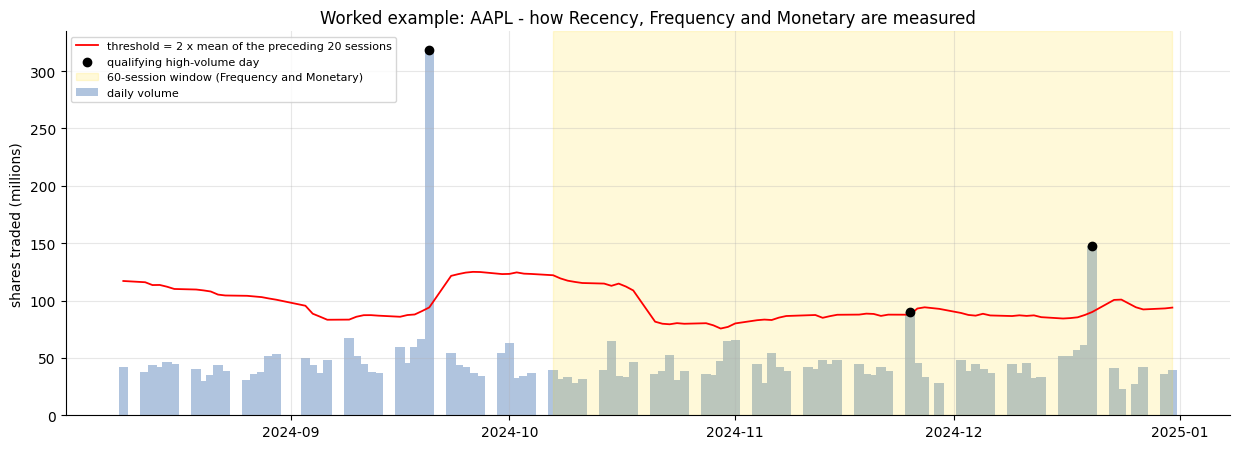

In [40]:
# TASK 1.5 | Part A: final feature table (one row per retained share) and worked RFM example
feature_table = (inclusion_log.loc[included, ["company", "sector"]]
                 .join(feat[["mean_weekly_return", "weekly_beta"]])
                 .join(rfm))
feature_table["last_event_date"] = OBS_DATE - pd.to_timedelta(feature_table["recency_days"], unit="D")
feature_table["log1p_monetary"] = np.log1p(feature_table["monetary_usd"])
# Optional extension columns for Task 2 experiments (market-wide days ignored). They are NOT part of the baseline features.
feature_table["recency_idio_days"] = recency_idio
feature_table["frequency_idio_60d"] = frequency_idio

core = ["mean_weekly_return", "weekly_beta", "recency_days", "frequency_60d", "monetary_usd"]
missing_rfm = feature_table[core].isna().any(axis=1)
check("no share is excluded for a missing feature value", not missing_rfm.any(), hard=False)
feature_table = feature_table.loc[~missing_rfm]          # a share with a missing value would leave the clustering set (none expected)
check("feature table index equals the retained share set", feature_table.index.tolist() == [t for t in included if t in feature_table.index])
print(f"Feature table: {feature_table.shape[0]} shares x {len(core)} core features")
feature_table.to_csv(f"{DATA_DIR}/feature_table.csv")

# Worked RFM example: the event rule applied day by day inside the window
ex = "AAPL" if "AAPL" in included else included[0]
wk = pd.DataFrame({"volume": v_inc[ex], "baseline_20d_mean": baseline[ex], "threshold_2x": threshold[ex], "event": flags[ex]}).loc[WIN]
wk["volume_over_threshold"] = wk["volume"] / wk["threshold_2x"]
print(f"\nWorked RFM example: {ex}")
print("Qualifying days in the 60-session window (volume above twice the mean of the preceding 20 sessions):")
print(wk[wk["event"]].round({"volume_over_threshold": 2, "baseline_20d_mean": 0, "threshold_2x": 0}).to_string())
near = wk[~wk["event"]].nlargest(1, "volume_over_threshold")
print("Closest day that did NOT qualify:")
print(near.round({"volume_over_threshold": 2, "baseline_20d_mean": 0, "threshold_2x": 0}).to_string())
row = feature_table.loc[ex]
print(f"R = {int(row['recency_days'])} calendar days (latest event {pd.Timestamp(row['last_event_date']).date()} to the observation date {OBS_DATE.date()}) | "
      f"F = {int(row['frequency_60d'])} days | M = ${row['monetary_usd'] / 1e9:,.1f} billion")

# Diagram of the worked example
vv, th, ff = v_inc[ex].iloc[-100:], threshold[ex].iloc[-100:], flags[ex].iloc[-100:]
fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.bar(vv.index, vv / 1e6, width=1.3, color="lightsteelblue", label="daily volume")
ax.plot(th.index, th / 1e6, color="red", lw=1.3, label="threshold = 2 x mean of the preceding 20 sessions")
ax.scatter(vv.index[ff.values], vv[ff.values] / 1e6, color="black", zorder=3, label="qualifying high-volume day")
ax.axvspan(WIN[0], WIN[-1], color="gold", alpha=0.15, label="60-session window (Frequency and Monetary)")
ax.set(title=f"Worked example: {ex} - how Recency, Frequency and Monetary are measured", ylabel="shares traded (millions)")
ax.legend(fontsize=8, loc="upper left")
save_fig("fig13_worked_example")

Feature summaries (monetary_usd in USD):
                      count                mean              median                  std                min                    max    skew
mean_weekly_return 486.0000              0.0029              0.0026               0.0027            -0.0045                 0.0178  0.8675
weekly_beta        486.0000              0.9737              0.9506               0.4073             0.0555                 3.7786  1.1036
recency_days       486.0000             20.4074             11.0000              21.3424             4.0000               222.0000  3.6458
frequency_60d      486.0000              2.9897              3.0000               1.3308             0.0000                 8.0000  0.4247
monetary_usd       486.0000 39,404,191,889.2078 16,683,821,504.6230 129,138,833,232.9717 1,297,482,617.0479 1,847,697,379,221.8428 11.6838


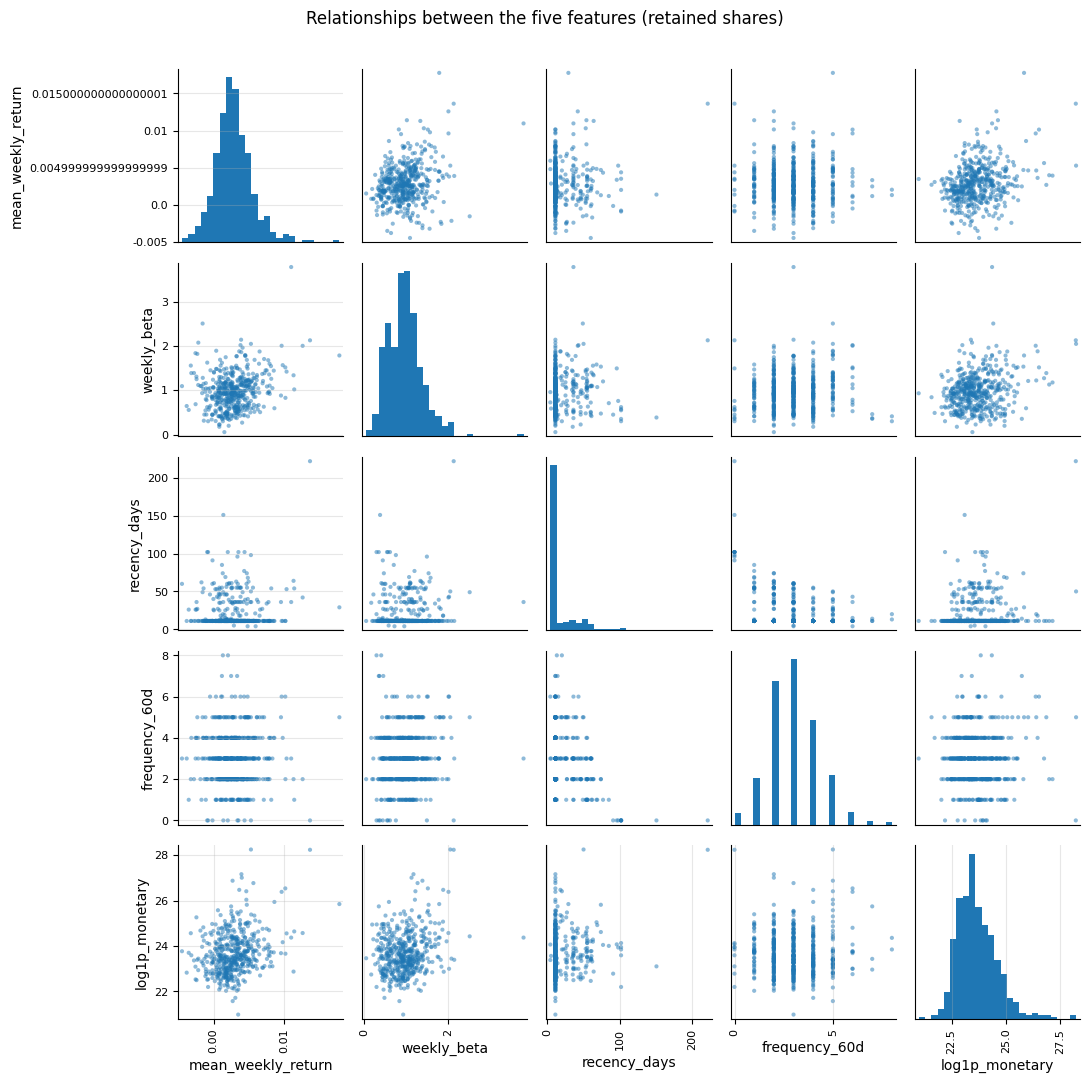


Validation and inclusion summary:
                                                          check                   result
                                       Snapshot retrieved (UTC)     2026-11-19 10:27 UTC
                                  Tickers in the Wikipedia list                      503
                        Excluded: no price data in study period                        5
                                   Excluded: incomplete history                       10
                      Excluded: volume error (zero or negative)                        2
                        Excluded: missing values inside history                        0
                    Shares retained (common set for all models)                      486
                      Duplicate dates on the benchmark calendar                        0
             Retained shares with missing values inside history                        0
                       Retained shares with non-positive prices            

In [41]:
# TASK 1.5 | Part B: feature summaries, relationships between the features, and the validation / inclusion summary
summ = feature_table[core].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T
print("Feature summaries (monetary_usd in USD):")
print(summ.to_string(float_format=lambda v: f"{v:,.4f}"))

plot_cols = ["mean_weekly_return", "weekly_beta", "recency_days", "frequency_60d", "log1p_monetary"]
pd.plotting.scatter_matrix(feature_table[plot_cols], figsize=(11, 11), diagonal="hist", alpha=0.5, hist_kwds={"bins": 25})
plt.suptitle("Relationships between the five features (retained shares)", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("figures/fig14_feature_scatter_matrix.png", dpi=150)
plt.show()

retained = chk.loc[included]
reason = inclusion_log["exclusion_reason"]
validation_summary = pd.DataFrame([
    ("Snapshot retrieved (UTC)", info["retrieved_utc"]),
    ("Tickers in the Wikipedia list", len(TICKERS)),
    ("Excluded: no price data in study period", int(reason.str.contains("No price data").sum())),
    ("Excluded: incomplete history", int(reason.str.contains("Incomplete history").sum())),
    ("Excluded: volume error (zero or negative)", int(reason.str.contains("Volume error").sum())),
    ("Excluded: missing values inside history", int(reason.str.contains("Missing values").sum())),
    ("Shares retained (common set for all models)", len(included)),
    ("Duplicate dates on the benchmark calendar", int(trading_days.duplicated().sum())),
    ("Retained shares with missing values inside history", int((retained["gaps"] > 0).sum())),
    ("Retained shares with non-positive prices", int((retained["nonpositive_price_days"] > 0).sum())),
    ("Retained shares with zero or negative volume days", int(((retained["zero_volume_days"] > 0) | (retained["negative_volume_days"] > 0)).sum())),
    ("Split-type corporate-action events among retained shares", int((spl > 0).sum().sum())),
    ("Days where Adj Close and Close differ without a recorded action", int(unexplained.sum().sum())),
    ("Aligned weekly return observations per share", int(N_WEEKS)),
    ("Observation date", OBS_DATE.date().isoformat()),
    ("60-session window", f"{WIN[0].date()} to {WIN[-1].date()}"),
    ("Testable share-days for the 20-session baseline", int(threshold.notna().sum().sum())),
    ("High-volume days flagged", int(flags.sum().sum())),
    ("Shares with no event in history (Recency missing)", int(recency.isna().sum())),
    ("Shares with Frequency = 0", int((frequency == 0).sum())),
], columns=["check", "result"])
print("\nValidation and inclusion summary:")
print(validation_summary.to_string(index=False))
validation_summary.to_csv(f"{DATA_DIR}/validation_summary.csv", index=False)

run_metadata = {"snapshot": info, "observation_date": OBS_DATE.date().isoformat(), "window": [WIN[0].date().isoformat(), WIN[-1].date().isoformat()],
                "shares_retained": len(included), "weekly_observations": int(N_WEEKS),
                "notebook_package_versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "yfinance": yf.__version__}}
json.dump(run_metadata, open(f"{DATA_DIR}/run_metadata.json", "w"), indent=2)
print("\nSaved: feature_table.csv, validation_summary.csv, inclusion_exclusion_log.csv, weekly_*.csv, high_volume_flags.csv, run_metadata.json in", DATA_DIR, "and diagrams in figures/")

In [42]:
# BACKUP | Zip data/ and figures/ (the snapshot plus every output). Set DOWNLOAD_BACKUP = True to download it from Colab
import zipfile
DOWNLOAD_BACKUP = False
zip_name = f"CWK1_snapshot_{info['retrieved_utc'][:10]}.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for folder, arc in [(DATA_DIR, "data"), ("figures", "figures")]:
        for p in sorted(glob.glob(f"{folder}/*")):
            z.write(p, f"{arc}/{os.path.basename(p)}")
print("Created", zip_name, f"({os.path.getsize(zip_name) / 1e6:.1f} MB)")
if DOWNLOAD_BACKUP:
    try:
        from google.colab import files
        files.download(zip_name)
    except ImportError:
        print("Not running in Colab: the zip is in the working folder.")

Created CWK1_snapshot_2026-11-19.zip (16.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>